# Houseplant SFT v2 — Colab T4: обучение + оценка

Один ноутбук: установка → pilot → полное QLoRA на `data/sft_v2/sft_train.jsonl` (1 060 пар, отбор судьёй, см. `reports/sft_v2_data.md`) → адаптер на Drive → base vs SFT на plant + garden + general, судья, правило выбора чекпоинта, test, графики.

Стек (pinned): `transformers==4.57.1` + `trl==0.24.0` + `peft==0.17.1` + `bitsandbytes` (Linux).

1. Runtime → Change runtime type → **T4 GPU**.
2. Secrets (ключ слева) → `OPENROUTER_API_KEY`, включить Notebook access.
3. Runtime → **Run all**. Вкладку не закрывать.

Повторный Run all безопасен: если адаптер уже на Drive (`MyDrive/rk1_houseplant/s2_sft_v2`), обучение пропускается; оценка пишется на Drive построчно и продолжает с места остановки.

- `SMOKE = True` — оценка по 3 примера на набор в отдельную папку (обучение не меняется).
- `FORCE_TRAIN = True` — переобучить, даже если адаптер на Drive уже есть.
- Старые `eval_s1` / `eval_smoke` не переиспользовать: другой системный промпт, база там оценена по-старому.
- Если после старого `--force-reinstall` сломан numpy/torch: Runtime → Disconnect and delete runtime. Не используйте `pip install -U` / `--force-reinstall` на весь файл требований.

In [1]:
from google.colab import drive, userdata
import os

SMOKE = False
FORCE_TRAIN = False

drive.mount('/content/drive')
DRIVE = '/content/drive/MyDrive/rk1_houseplant'
ADAPTER = f'{DRIVE}/s2_sft_v2'
OUT = f'{DRIVE}/eval_smoke_s2' if SMOKE else f'{DRIVE}/eval_s2'
os.environ['OPENROUTER_API_KEY'] = userdata.get('OPENROUTER_API_KEY')
os.makedirs(OUT, exist_ok=True)
TRAIN = FORCE_TRAIN or not os.path.exists(f'{ADAPTER}/adapter_model.safetensors')
print('train:', TRAIN, '| adapter:', ADAPTER, '| out:', OUT)

Mounted at /content/drive
train: False | adapter: /content/drive/MyDrive/rk1_houseplant/s2_sft_v2 | out: /content/drive/MyDrive/rk1_houseplant/eval_s2


In [2]:
%cd /content
!git clone https://github.com/Schaft-s/LLM || (cd LLM && git pull)
%cd /content/LLM
import sys
sys.path.insert(0, '/content/LLM')
!wc -l data/sft_v2/sft_train.jsonl  # expect 1060
# Safe install: only our pins. Needs bitsandbytes>=0.49.2 for Colab CUDA 13.
!bash scripts/colab_install.sh
!python scripts/smoke_colab_stack.py
!git rev-parse HEAD > "{OUT}/git_commit.txt"
!mkdir -p "{OUT}/configs" && cp configs/*.yaml "{OUT}/configs/"
!nvidia-smi --query-gpu=name,memory.total --format=csv > "{OUT}/gpu.txt"

/content
Cloning into 'LLM'...
remote: Enumerating objects: 239, done.
remote: Counting objects: 100% (239/239), done.
remote: Compressing objects: 100% (162/162), done.
remote: Total 239 (delta 104), reused 201 (delta 66), pack-reused 0 (from 0)
Receiving objects: 100% (239/239), 3.69 MiB | 17.74 MiB/s, done.
Resolving deltas: 100% (104/104), done.
/content/LLM
1060 data/sft_v2/sft_train.jsonl
Found existing installation: transformers 5.22.1
Uninstalling transformers-5.22.1:
  Successfully uninstalled transformers-5.22.1
Found existing installation: peft 0.21.2
Uninstalling peft-0.21.2:
  Successfully uninstalled peft-0.21.2
Found existing installation: accelerate 1.15.0
Uninstalling accelerate-1.15.0:
  Successfully uninstalled accelerate-1.15.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have h

## Pilot (20 steps) → reload + 1 generation

In [3]:
import subprocess

def run(cmd, log):
    # stream output to the cell and to a log on Drive; fail the cell on error
    with open(log, 'a') as f:
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        for line in p.stdout:
            print(line, end=''); f.write(line)
    if p.wait():
        raise SystemExit(f'{cmd} failed, see {log}')

if TRAIN:
    run([sys.executable, 'scripts/train_qlora.py', '--pilot'], f'{OUT}/train_pilot.log')
    from src.train.generate import generate_chat, load_base_or_adapter
    from src.train.sft_qlora import load_yaml
    import gc, torch
    model_cfg = load_yaml('configs/model.yaml')
    model, tok = load_base_or_adapter(model_cfg, adapter_dir='artifacts/weights/pilot_qlora')
    print(generate_chat(
        model, tok,
        'My snake plant has mushy leaves at the base after weekly watering in low light. What should I check first?',
        system_prompt=model_cfg.get('system_prompt', '').strip(),
        max_new_tokens=256, temperature=0.2,
    ))
    del model; gc.collect(); torch.cuda.empty_cache()
else:
    print('adapter already on Drive → skip pilot')

adapter already on Drive → skip pilot


## S2: полное QLoRA на SFT v2 → копия на Drive

In [4]:
if TRAIN:
    run([sys.executable, 'scripts/train_qlora.py'], f'{OUT}/train_s2.log')
    !rm -rf "{ADAPTER}" && cp -r artifacts/weights/s2_sft_v2 "{ADAPTER}"
print(sorted(os.listdir(ADAPTER)))
assert os.path.exists(f'{ADAPTER}/adapter_model.safetensors')

['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'added_tokens.json', 'chat_template.jinja', 'checkpoint-100', 'checkpoint-133', 'checkpoint-50', 'merges.txt', 'special_tokens_map.json', 'tokenizer.json', 'tokenizer_config.json', 'vocab.json']


## Оценка: base vs SFT

Генерация → автопроверка `no_invented_experience` → судья (OpenRouter) → правило выбора чекпоинта (судья по plant_dev ∪ garden_dev не хуже базы; general_dev не падает больше чем на 5 п.п.) → test → графики. Возобновляемо.

In [5]:
LIMIT = '--limit 3' if SMOKE else ''
!python scripts/run_eval_pipeline.py --out-dir "{OUT}" --adapter-root "{ADAPTER}" {LIMIT} 2>&1 | tee -a "{OUT}/run.log"

[17:49:48] candidates: ['sft_final', 'sft_step50', 'sft_step100']
I0000 00:00:1794246595.927639    1469 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794246598.563009    1469 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Loading checkpoint shards: 100%|██████████| 2/2 [00:27<00:00, 13.63s/it]
[17:52:04] == baseline samples
[17:52:05]   baseline_samples__base.jsonl: already complete (2)
[17:52:06]   baseline_samples__sft_final.jsonl: already complete (2)
[17:52:06] == dev / base
[17:52:07]   general_dev__base.jsonl: already complete (80)
[17:52:07]   plant_dev__base.jsonl: already complete (39)
[17:52:08]   judge_plant_dev__base.jsonl: judged 39/39
[17:52:09]   garden_dev__base.jsonl: already complete (40)
[17:52:10]   

# RK1 eval summary

Selected: **base**


## dev

| variant | general acc | no invented exp | judge plant | judge garden | judge all (0-8) | critical err | c→w | w→c |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| base | 0.800 | 1.00 | 6.67 | 6.78 | 6.72 | 0.01 | - | - |
| sft_final | 0.863 | 0.96 | 3.90 | 4.28 | 4.09 | 0.16 | 2 | 7 |
| sft_step50 | 0.863 | 0.91 | 3.23 | 3.95 | 3.59 | 0.19 | 2 | 7 |
| sft_step100 | 0.863 | 0.96 | 3.56 | 4.22 | 3.90 | 0.22 | 2 | 7 |

Per-category general accuracy:

| variant | arc_easy | arith | extract | json_schema | logic | stable_facts | units |
|---|---:|---:|---:|---:|---:|---:|---:|
| base | 0.95 | 0.70 | 1.00 | 1.00 | 0.60 | 0.80 | 0.40 |
| sft_final | 0.95 | 0.70 | 1.00 | 1.00 | 0.70 | 1.00 | 0.60 |
| sft_step50 | 0.95 | 0.70 | 1.00 | 1.00 | 0.70 | 1.00 | 0.60 |
| sft_step100 | 0.95 | 0.70 | 1.00 | 1.00 | 0.70 | 1.00 | 0.60 |

## test

| variant | general acc | no invented exp | judge plant | judge garden | judge all (0-8) | critical err | c→w | w→c |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| base | 0.819 | 1.00 | 6.64 | 6.92 | 6.78 | 0.01 | - | - |
| sft_final | 0.850 | 0.97 | 3.97 | 3.92 | 3.95 | 0.14 | 4 | 9 |

Per-category general accuracy:

| variant | arc_easy | arith | extract | json_schema | logic | stable_facts | units |
|---|---:|---:|---:|---:|---:|---:|---:|
| base | 0.93 | 0.95 | 1.00 | 1.00 | 0.45 | 0.85 | 0.45 |
| sft_final | 0.95 | 0.85 | 1.00 | 1.00 | 0.60 | 0.85 | 0.60 |

- rule check `sft_final`: pass=False {"general_drop_pp": -6.25, "general_ok": true, "plant_ok": false, "plant_basis": "judge_mean_total_plant+garden"}

- rule check `sft_step50`: pass=False {"general_drop_pp": -6.25, "general_ok": true, "plant_ok": false, "plant_basis": "judge_mean_total_plant+garden"}

- rule check `sft_step100`: pass=False {"general_drop_pp": -6.25, "general_ok": true, "plant_ok": false, "plant_basis": "judge_mean_total_plant+garden"}


/content/drive/MyDrive/rk1_houseplant/eval_s2/plots/general_dev_per_category.png


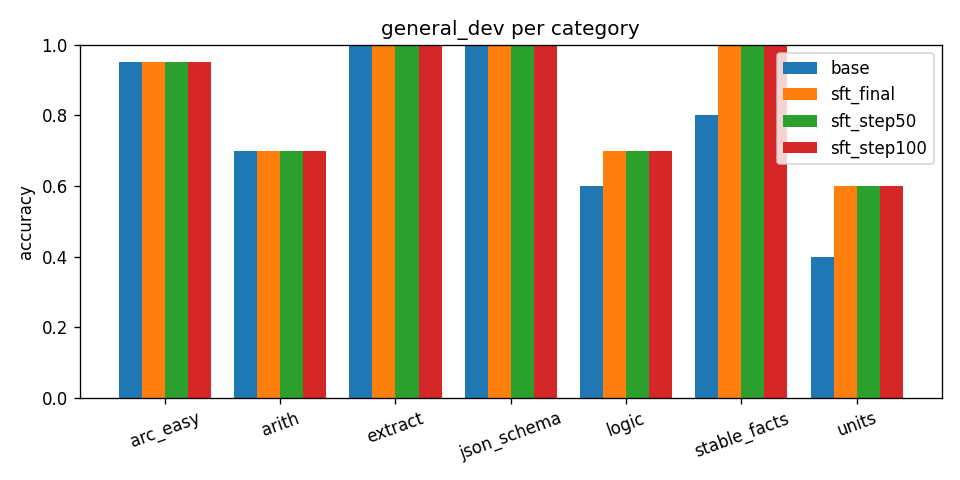

/content/drive/MyDrive/rk1_houseplant/eval_s2/plots/general_test_per_category.png


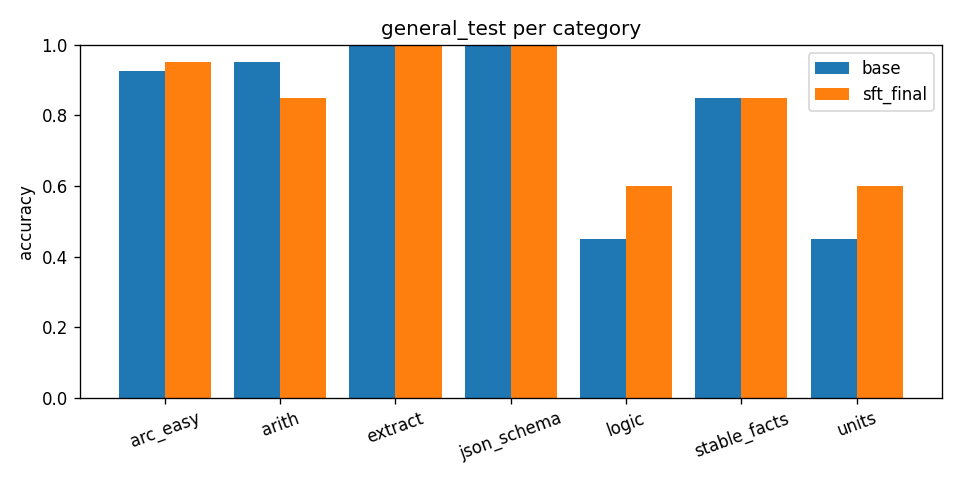

/content/drive/MyDrive/rk1_houseplant/eval_s2/plots/judge_plant_dev.png


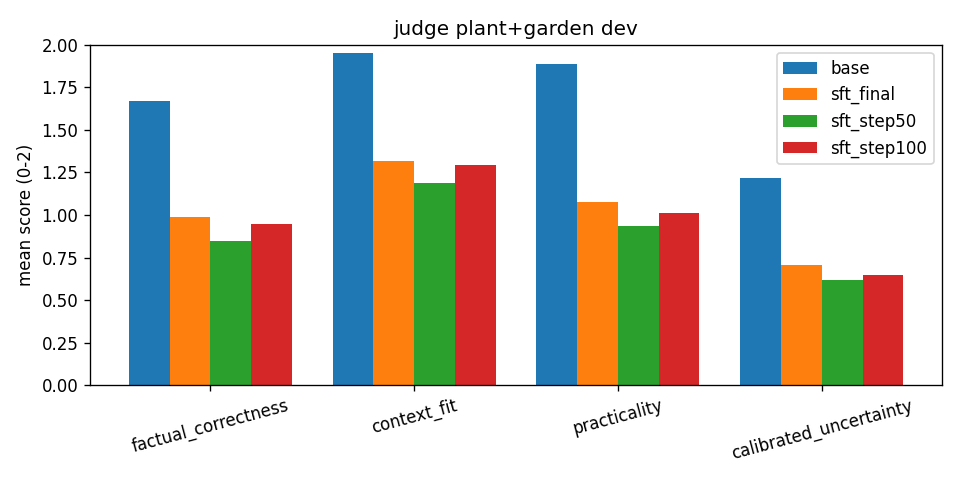

/content/drive/MyDrive/rk1_houseplant/eval_s2/plots/judge_plant_test.png


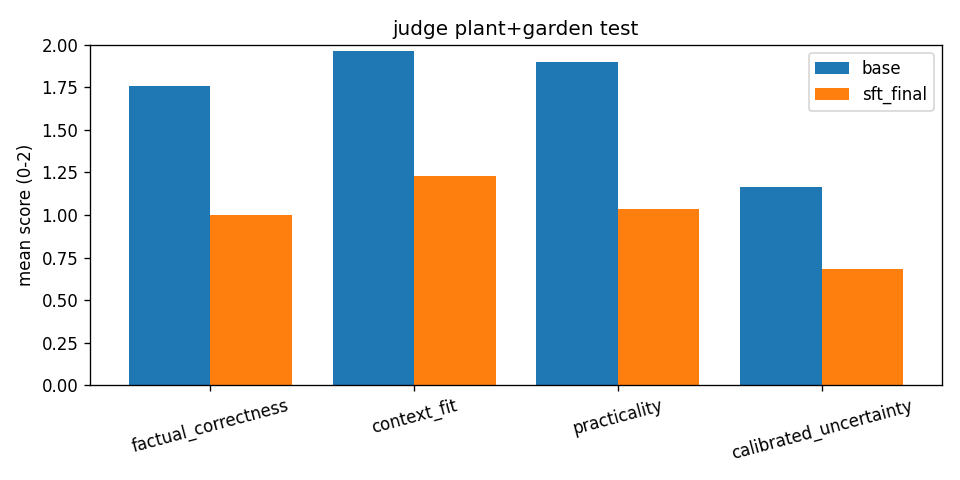

/content/drive/MyDrive/rk1_houseplant/eval_s2/plots/train_loss.png


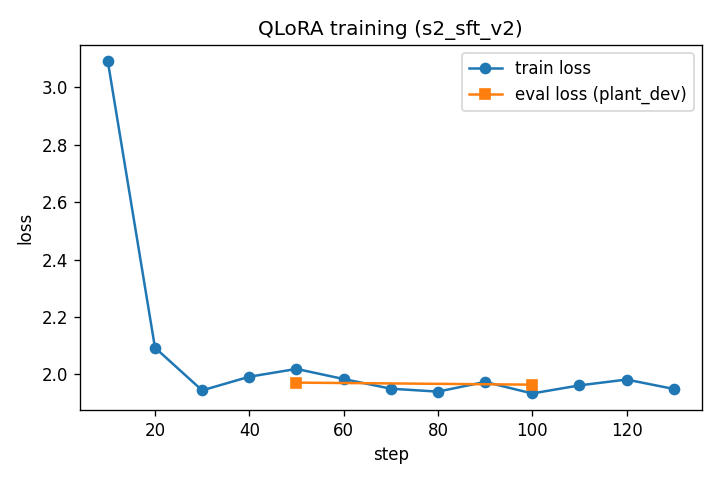

Drive flushed


In [6]:
import glob
from IPython.display import Image, Markdown, display

display(Markdown(open(f'{OUT}/summary.md').read()))
for p in sorted(glob.glob(f'{OUT}/plots/*.png')):
    print(p)
    display(Image(p))
drive.flush_and_unmount()
print('Drive flushed')